# ASTR 5820 Problem Set 4

## 1. Build the Module

github repo: https://github.com/rhaliattar/astr5820.git

### test 1

In [21]:
import numpy as np
from astrotools.nbody import drag

y = drag.initial_state(1.0, 0.1, 0.41)
vx, vy, ax, ay = drag.hill_drag_derivs(0, y, 0.1, 0.41)

print('|x_double_dot| =', np.abs(ax))
print('|y_double_dot + 3/2 * x_dot| =', np.abs(ay + 3/2 * vx))
print("Planet's pull, 3/r^2 =", 3/(y[0]**2 + y[1]**2))

|x_double_dot| = 0.001718182341801544
|y_double_dot + 3/2 * x_dot| = 0.020618188101618223
Planet's pull, 3/r^2 = 0.020689655172413793


### test 2

In [24]:
from astrotools.nbody import integrators

initial_state_captured = drag.initial_state(1.0, 0.1, 0.41)
initial_state_not_captured = drag.initial_state(2.0, 0.1, 0.41)

func = lambda t, y: drag.hill_drag_derivs(t, y, 0.1, 0.41)

captured = drag.encounter(integrators.rk4_step, func, initial_state_captured, 0.05)
not_captured = drag.encounter(integrators.rk4_step, func, initial_state_not_captured, 0.05)

print('A pebble starting at x_0 = 1.0 was captured:', captured[0])
print('A pebble starting at x_0 = 2.0 was captured:', not_captured[0])

A pebble starting at x_0 = 1.0 was captured: True
A pebble starting at x_0 = 2.0 was captured: False


## 2. Capturing Pebbles

### Part (a)

Numerical Accretion Rate = 1.3653258212850574 [Sigma_peb.Omega_k.r_H^2]
Analytical Accretion Rate = 1.3444214239671497 [Sigma_peb.Omega_k.r_H^2]


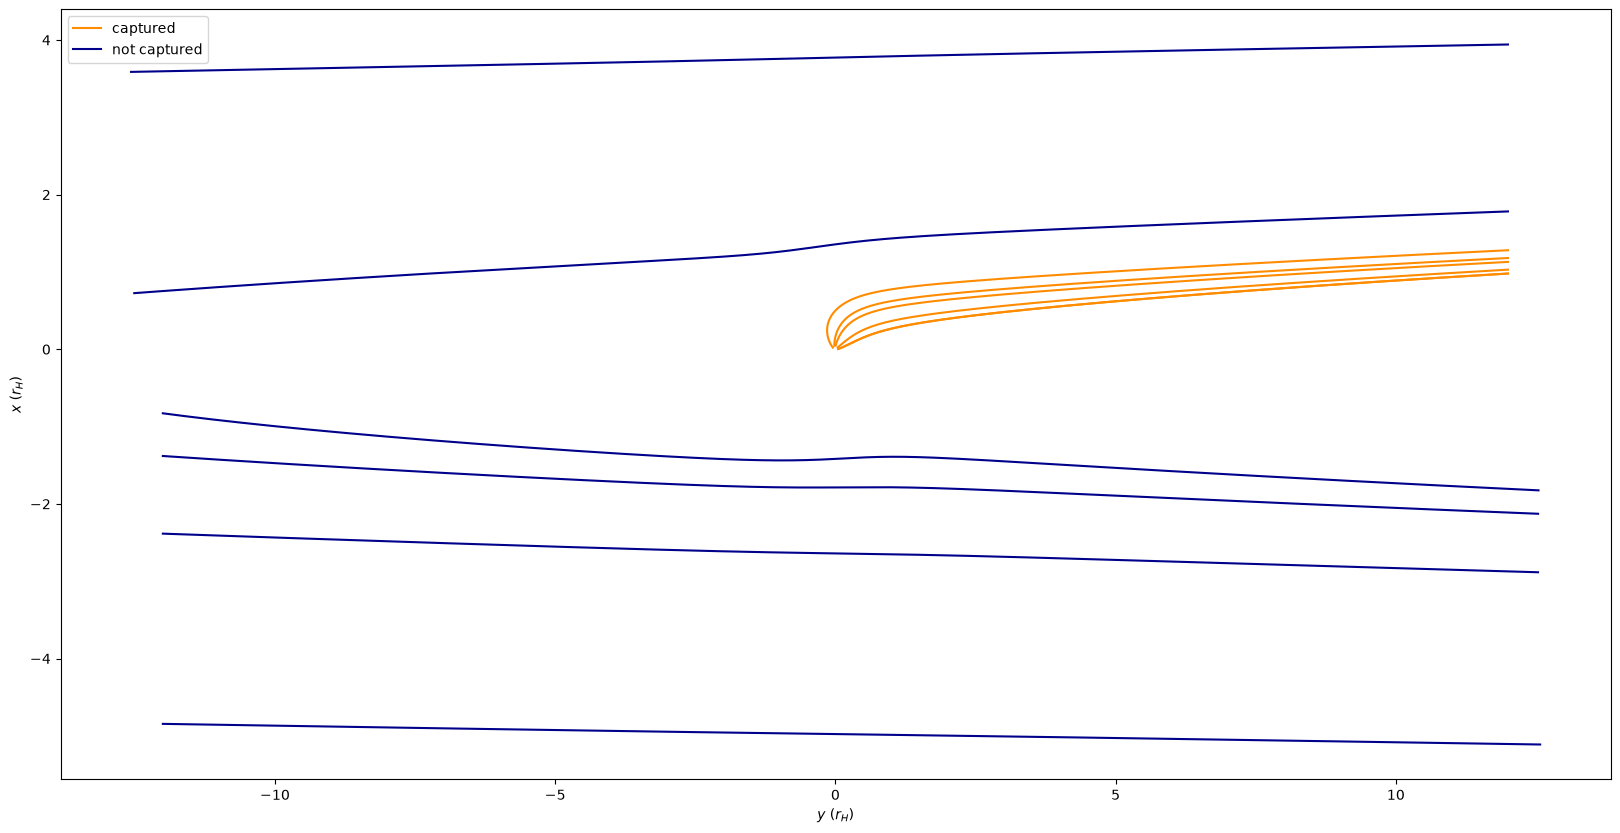

In [263]:
import matplotlib.pyplot as plt

np.random.seed(7)

headwind = 0.41
st = 0.1
r_cap = 0.05
dx_0 = 0.05

analytical_M_dot = 3 * (3*st)**(2/3)

func = lambda t, y: drag.hill_drag_derivs(t, y, st, headwind)

all_x_0s = np.linspace(-6, 6, int(12/dx_0))

all_initial_states = np.asarray([drag.initial_state(all_x_0s[i], st, headwind) for i in range(len(all_x_0s))])

all_encounters = [drag.encounter(integrators.rk4_step, func, all_initial_states[i], r_cap) for i in range(len(all_initial_states))] 
capture = np.asarray([all_encounters[i][0] for i in range(len(all_encounters))])

numerical_M_dot = np.sum(np.abs(all_initial_states[np.where(capture == True)][:, -1])*dx_0)

plt.figure(figsize = (20, 10))

captured_set = np.random.choice(np.where(capture == True)[0], 6)
not_captured_set = np.random.choice(np.where(capture == False)[0], 6)

for i in range(6):
    if i == 0:
        plt.plot(np.transpose(all_encounters[captured_set[i]][2])[1], np.transpose(all_encounters[captured_set[i]][2])[0], color = 'darkorange', label = 'captured')
        plt.plot(np.transpose(all_encounters[not_captured_set[i]][2])[1], np.transpose(all_encounters[not_captured_set[i]][2])[0], color = 'darkblue', label = 'not captured')
    else:
        plt.plot(np.transpose(all_encounters[captured_set[i]][2])[1], np.transpose(all_encounters[captured_set[i]][2])[0], color = 'darkorange')
        plt.plot(np.transpose(all_encounters[not_captured_set[i]][2])[1], np.transpose(all_encounters[not_captured_set[i]][2])[0], color = 'darkblue')

plt.legend()
plt.xlabel(r'$y$ ($r_H$)')
plt.ylabel(r'$x$ ($r_H$)')

print('Numerical Accretion Rate =', numerical_M_dot, '[Sigma_peb.Omega_k.r_H^2]')
print('Analytical Accretion Rate =', analytical_M_dot, '[Sigma_peb.Omega_k.r_H^2]')


### Part (b)

Numerical Accretion Rate = 3.1033326359832634 [Sigma_peb.Omega_k.r_H^2]
Analytical Accretion Rate = 6.240251469155712 [Sigma_peb.Omega_k.r_H^2]


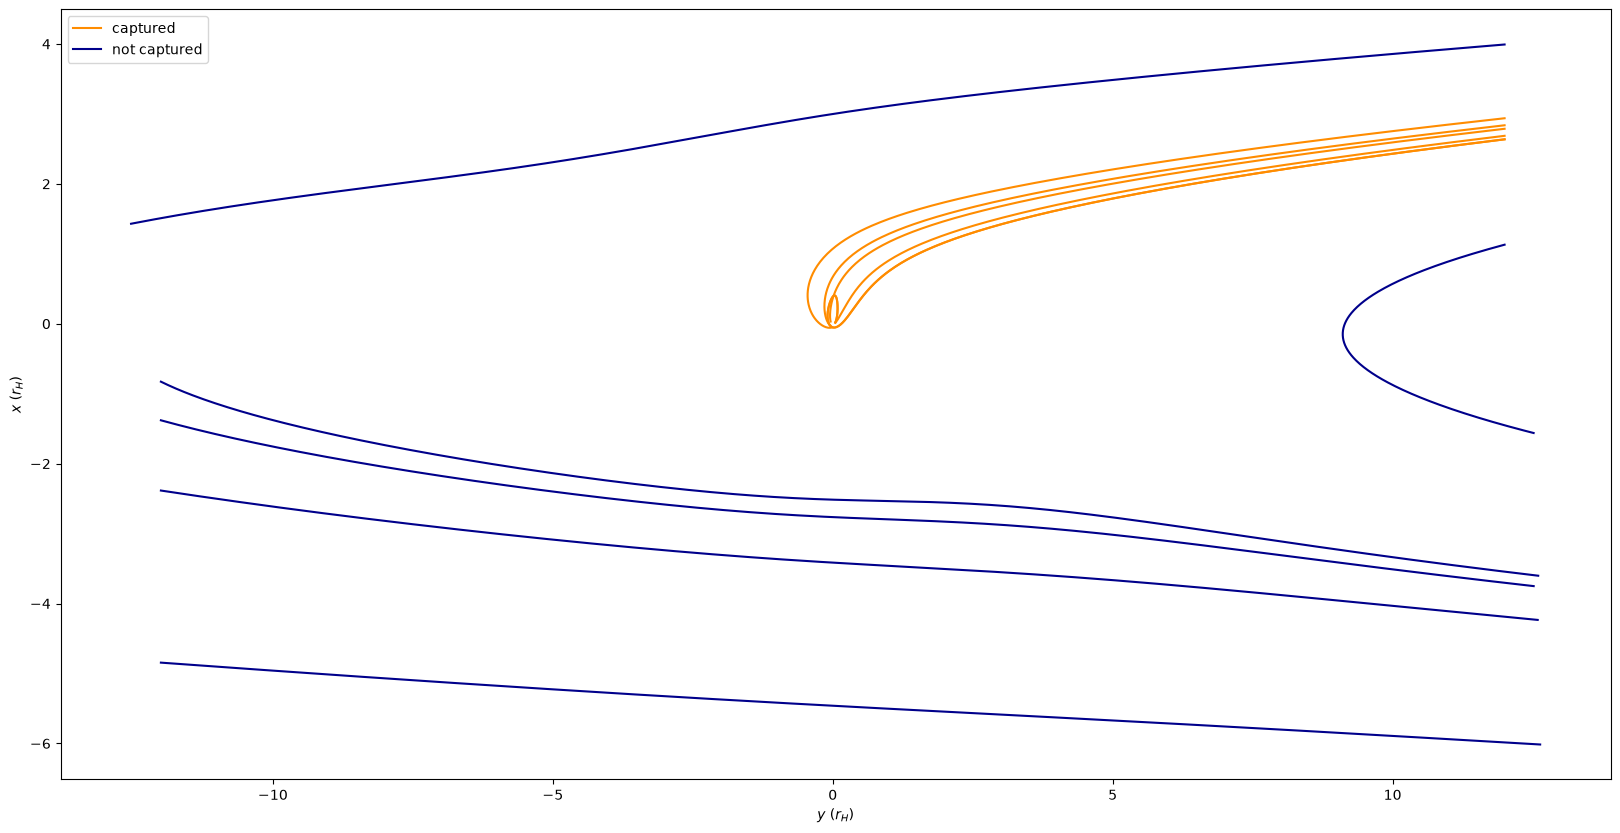

In [264]:
np.random.seed(7)

headwind = 0.41
st = 1
r_cap = 0.05
dx_0 = 0.05

analytical_M_dot = 3 * (3*st)**(2/3)

func = lambda t, y: drag.hill_drag_derivs(t, y, st, headwind)

all_x_0s = np.linspace(-6, 6, int(12/dx_0))

all_initial_states = np.asarray([drag.initial_state(all_x_0s[i], st, headwind) for i in range(len(all_x_0s))])

all_encounters = [drag.encounter(integrators.rk4_step, func, all_initial_states[i], r_cap) for i in range(len(all_initial_states))] 
capture = np.asarray([all_encounters[i][0] for i in range(len(all_encounters))])

numerical_M_dot = np.sum(np.abs(all_initial_states[np.where(capture == True)][:, -1])*dx_0)

plt.figure(figsize = (20, 10))

captured_set = np.random.choice(np.where(capture == True)[0], 6)
not_captured_set = np.random.choice(np.where(capture == False)[0], 6)

for i in range(6):
    if i == 0:
        plt.plot(np.transpose(all_encounters[captured_set[i]][2])[1], np.transpose(all_encounters[captured_set[i]][2])[0], color = 'darkorange', label = 'captured')
        plt.plot(np.transpose(all_encounters[not_captured_set[i]][2])[1], np.transpose(all_encounters[not_captured_set[i]][2])[0], color = 'darkblue', label = 'not captured')
    else:
        plt.plot(np.transpose(all_encounters[captured_set[i]][2])[1], np.transpose(all_encounters[captured_set[i]][2])[0], color = 'darkorange')
        plt.plot(np.transpose(all_encounters[not_captured_set[i]][2])[1], np.transpose(all_encounters[not_captured_set[i]][2])[0], color = 'darkblue')

plt.legend()
plt.xlabel(r'$y$ ($r_H$)')
plt.ylabel(r'$x$ ($r_H$)')

print('Numerical Accretion Rate =', numerical_M_dot, '[Sigma_peb.Omega_k.r_H^2]')
print('Analytical Accretion Rate =', analytical_M_dot, '[Sigma_peb.Omega_k.r_H^2]')


The captured bands lie at larger $x_0$ values due to the equation for pebble accretion $b_{sh} = (3 St)^{1/3} r_H$. So, at larger St values, we expect a larger maximum impact parameter $b_{sh}$. The analytical accretion rate gets further away from the numerical one because pebble accretion is more inefficient at larger St (efficiency factor $\epsilon \propto St^2$).

### Part (c)

Numerical Accretion Rate = 3.1033326359832634 [Sigma_peb.Omega_k.r_H^2]
Analytical Accretion Rate = 6.240251469155712 [Sigma_peb.Omega_k.r_H^2]


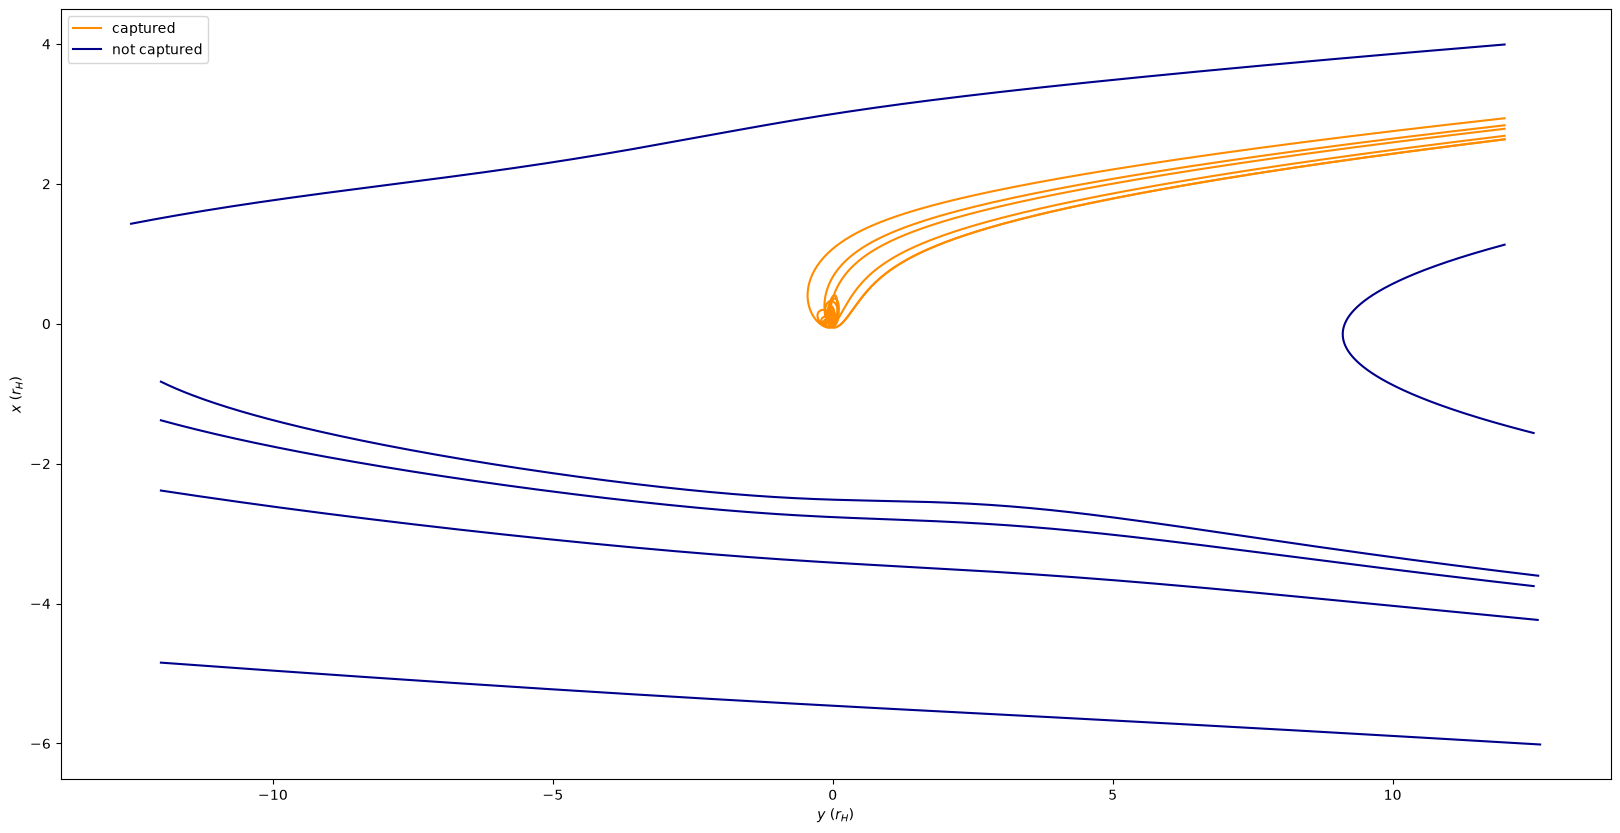

In [265]:
np.random.seed(7)

headwind = 0.41
st = 1
r_cap = 0.01
dx_0 = 0.05

analytical_M_dot = 3 * (3*st)**(2/3)

func = lambda t, y: drag.hill_drag_derivs(t, y, st, headwind)

all_x_0s = np.linspace(-6, 6, int(12/dx_0))

all_initial_states = np.asarray([drag.initial_state(all_x_0s[i], st, headwind) for i in range(len(all_x_0s))])

all_encounters = [drag.encounter(integrators.rk4_step, func, all_initial_states[i], r_cap) for i in range(len(all_initial_states))] 
capture = np.asarray([all_encounters[i][0] for i in range(len(all_encounters))])

numerical_M_dot = np.sum(np.abs(all_initial_states[np.where(capture == True)][:, -1])*dx_0)

plt.figure(figsize = (20, 10))

captured_set = np.random.choice(np.where(capture == True)[0], 6)
not_captured_set = np.random.choice(np.where(capture == False)[0], 6)

for i in range(6):
    if i == 0:
        plt.plot(np.transpose(all_encounters[captured_set[i]][2])[1], np.transpose(all_encounters[captured_set[i]][2])[0], color = 'darkorange', label = 'captured')
        plt.plot(np.transpose(all_encounters[not_captured_set[i]][2])[1], np.transpose(all_encounters[not_captured_set[i]][2])[0], color = 'darkblue', label = 'not captured')
    else:
        plt.plot(np.transpose(all_encounters[captured_set[i]][2])[1], np.transpose(all_encounters[captured_set[i]][2])[0], color = 'darkorange')
        plt.plot(np.transpose(all_encounters[not_captured_set[i]][2])[1], np.transpose(all_encounters[not_captured_set[i]][2])[0], color = 'darkblue')

plt.legend()
plt.xlabel(r'$y$ ($r_H$)')
plt.ylabel(r'$x$ ($r_H$)')

print('Numerical Accretion Rate =', numerical_M_dot, '[Sigma_peb.Omega_k.r_H^2]')
print('Analytical Accretion Rate =', analytical_M_dot, '[Sigma_peb.Omega_k.r_H^2]')


In [266]:
np.random.seed(7)

headwind = 0
st = 1e6
r_cap_5 = 0.05
r_cap_1 = 0.01
dx_0 = 0.02

analytical_M_dot = 3 * (3*st)**(2/3)

func = lambda t, y: drag.hill_drag_derivs(t, y, st, headwind)

all_x_0s = np.linspace(-3, 3, int(6/dx_0))

all_initial_states = np.asarray([drag.initial_state(all_x_0s[i], st, headwind) for i in range(len(all_x_0s))])

all_encounters_5 = [drag.encounter(integrators.rk4_step, func, all_initial_states[i], r_cap_5) for i in range(len(all_initial_states))] 
capture_5 = np.asarray([all_encounters_5[i][0] for i in range(len(all_encounters_5))])

all_encounters_1 = [drag.encounter(integrators.rk4_step, func, all_initial_states[i], r_cap_1) for i in range(len(all_initial_states))] 
capture_1 = np.asarray([all_encounters_1[i][0] for i in range(len(all_encounters_1))])

numerical_M_dot_5 = np.sum(np.abs(all_initial_states[np.where(capture_5 == True)][:, -1])*dx_0)
numerical_M_dot_1 = np.sum(np.abs(all_initial_states[np.where(capture_1 == True)][:, -1])*dx_0)

print('Numerical Accretion Rate (r_cap = 0.05) =', numerical_M_dot_5, '[Sigma_peb.Omega_k.r_H^2]')
print('Numerical Accretion Rate (r_cap = 0.01) =', numerical_M_dot_1, '[Sigma_peb.Omega_k.r_H^2]')


Numerical Accretion Rate (r_cap = 0.05) = 2.582006688963211 [Sigma_peb.Omega_k.r_H^2]
Numerical Accretion Rate (r_cap = 0.01) = 0.98247491638796 [Sigma_peb.Omega_k.r_H^2]


Without gas, a smaller $r_{cap}$ reduces the accretion rate; but with gas $r_{cap}$ doesn't matter. This is because with gas, once the pebble has slowed down enough due to drag, it will be accreted; but without gas, a pebble could come very close to a protoplanet and not get accreted if it is moving faster than the escape velocity. With larger $r_{cap}$, we're considering these latter pebbles to have accreted, even when they haven't actually hit the surface of the protoplanet.

## 3. Holding Trojans

### Part (a)

In [259]:
import rebound
sim = rebound.Simulation()
sim.units = ("yr", "AU", "Msun")

mu = 9.54e-4
a = 5.2

L4 = (a*(0.5 - mu), np.sqrt(3)/2 * a)
epsilon = 1e-3
omega = np.sqrt(sim.G/a**3)

sim.add(m=1.0-mu, x=-mu*a, y=0, vy=-mu*a*omega)
sim.add(m=mu, x=(1-mu)*a, y=0, vy=(1-mu)*a*omega)
sim.add(m=0, x = a*epsilon + L4[0], y = a*epsilon + L4[1], vx = -(L4[1] + a*epsilon) * omega, vy = (L4[0] + a*epsilon) * omega)
sim.move_to_com()

measured synodic period 147.5 yr; predicted 147.8 yr
Range of \phi: 53.9 to 66.7 deg


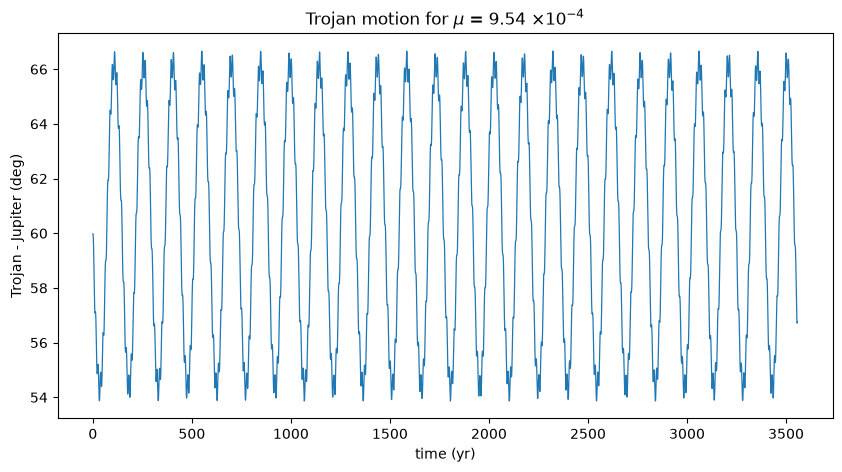

In [260]:
P_planet = sim.particles[1].orbit(primary=sim.particles[0]).P

times = np.linspace(0, P_planet*300, 3000)
xy = np.empty((len(times), 3, 2))

sim.integrator = "ias15"
for k, t in enumerate(times):
    sim.integrate(t)
    for i, p in enumerate(sim.particles):
        xy[k, i] = p.x, p.y

def angle_from_star(xy, i, j):
    """Angle of body j relative to body i as seen from body 0, in degrees."""
    d_i = xy[:, i] - xy[:, 0]
    d_j = xy[:, j] - xy[:, 0]
    ang = np.arctan2(d_j[:, 1], d_j[:, 0]) - np.arctan2(d_i[:, 1], d_i[:, 0])
    return np.degrees((ang + np.pi) % (2 * np.pi) - np.pi)

phi = angle_from_star(xy, 1, 2)

cross = np.where((phi[:-1] > np.average(phi)) & (phi[1:] <= np.average(phi)))[0]
P_J, P_test = (sim.particles[i].orbit(primary=sim.particles[0]).P for i in (1, 2))
print(f"measured synodic period {np.mean(np.diff(times[cross])):.1f} yr; "
      f"predicted {P_planet/(np.sqrt(27*mu/4)):.1f} yr")
print(r"Range of \phi:" f" {np.min(phi):.1f} " r"to" f" {np.max(phi):.1f} deg")
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, phi, lw=0.9)
ax.set(xlabel="time (yr)", ylabel="Trojan - Jupiter (deg)", title=r"Trojan motion for $\mu$ = 9.54 $\times 10^{-4}$")
plt.show()

### Part (b)

measured synodic period 22.9 yr; predicted 26.4 yr
Range of \phi: 57.1 to 63.2 deg


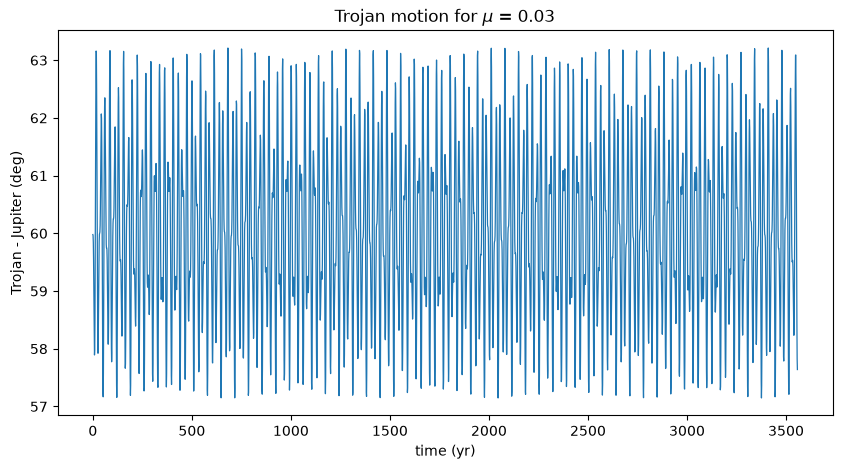

In [261]:
import rebound
sim = rebound.Simulation()
sim.units = ("yr", "AU", "Msun")

mu = 0.03
a = 5.2

L4 = (a*(0.5 - mu), np.sqrt(3)/2 * a)
epsilon = 1e-3
omega = np.sqrt(sim.G/a**3)

sim.add(m=1.0-mu, x=-mu*a, y=0, vy=-mu*a*omega)
sim.add(m=mu, x=(1-mu)*a, y=0, vy=(1-mu)*a*omega)
sim.add(m=0, x = a*epsilon + L4[0], y = a*epsilon + L4[1], vx = -(L4[1] + a*epsilon) * omega, vy = (L4[0] + a*epsilon) * omega)
sim.move_to_com()

P_planet = sim.particles[1].orbit(primary=sim.particles[0]).P

times = np.linspace(0, P_planet*300, 3000)
xy = np.empty((len(times), 3, 2))

sim.integrator = "ias15"
for k, t in enumerate(times):
    sim.integrate(t)
    for i, p in enumerate(sim.particles):
        xy[k, i] = p.x, p.y

def angle_from_star(xy, i, j):
    """Angle of body j relative to body i as seen from body 0, in degrees."""
    d_i = xy[:, i] - xy[:, 0]
    d_j = xy[:, j] - xy[:, 0]
    ang = np.arctan2(d_j[:, 1], d_j[:, 0]) - np.arctan2(d_i[:, 1], d_i[:, 0])
    return np.degrees((ang + np.pi) % (2 * np.pi) - np.pi)

phi = angle_from_star(xy, 1, 2)

cross = np.where((phi[:-1] > np.average(phi)) & (phi[1:] <= np.average(phi)))[0]
P_J, P_test = (sim.particles[i].orbit(primary=sim.particles[0]).P for i in (1, 2))
print(f"measured synodic period {np.mean(np.diff(times[cross])):.1f} yr; "
      f"predicted {P_planet/(np.sqrt(27*mu/4)):.1f} yr")
print(r"Range of \phi:" f" {np.min(phi):.1f} " r"to" f" {np.max(phi):.1f} deg")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, phi, lw=0.9)
ax.set(xlabel="time (yr)", ylabel="Trojan - Jupiter (deg)", title=r"Trojan motion for $\mu$ = 0.03")
plt.show()

measured synodic period 12.0 yr; predicted 20.4 yr
Range of \phi: -180.0 to 179.9 deg


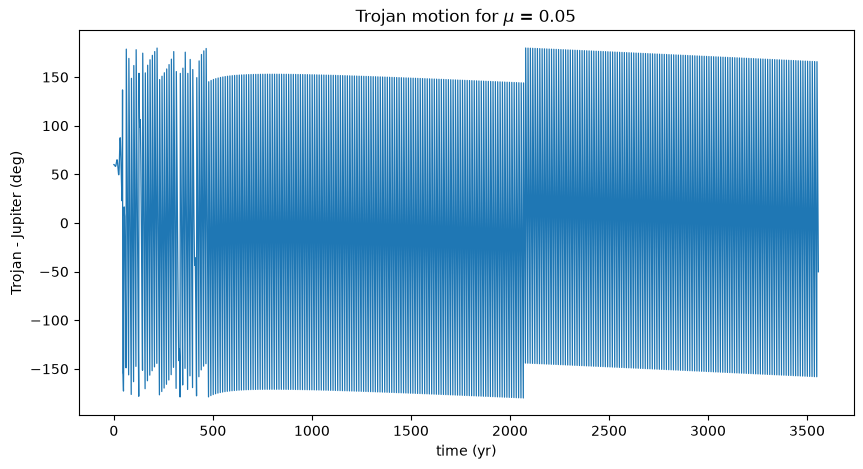

In [262]:
import rebound
sim = rebound.Simulation()
sim.units = ("yr", "AU", "Msun")

mu = 0.05
a = 5.2

L4 = (a*(0.5 - mu), np.sqrt(3)/2 * a)
epsilon = 1e-3
omega = np.sqrt(sim.G/a**3)

sim.add(m=1.0-mu, x=-mu*a, y=0, vy=-mu*a*omega)
sim.add(m=mu, x=(1-mu)*a, y=0, vy=(1-mu)*a*omega)
sim.add(m=0, x = a*epsilon + L4[0], y = a*epsilon + L4[1], vx = -(L4[1] + a*epsilon) * omega, vy = (L4[0] + a*epsilon) * omega)
sim.move_to_com()

P_planet = sim.particles[1].orbit(primary=sim.particles[0]).P

times = np.linspace(0, P_planet*300, 3000)
xy = np.empty((len(times), 3, 2))

sim.integrator = "ias15"
for k, t in enumerate(times):
    sim.integrate(t)
    for i, p in enumerate(sim.particles):
        xy[k, i] = p.x, p.y

def angle_from_star(xy, i, j):
    """Angle of body j relative to body i as seen from body 0, in degrees."""
    d_i = xy[:, i] - xy[:, 0]
    d_j = xy[:, j] - xy[:, 0]
    ang = np.arctan2(d_j[:, 1], d_j[:, 0]) - np.arctan2(d_i[:, 1], d_i[:, 0])
    return np.degrees((ang + np.pi) % (2 * np.pi) - np.pi)

phi = angle_from_star(xy, 1, 2)

cross = np.where((phi[:-1] > np.average(phi)) & (phi[1:] <= np.average(phi)))[0]
P_J, P_test = (sim.particles[i].orbit(primary=sim.particles[0]).P for i in (1, 2))
print(f"measured synodic period {np.mean(np.diff(times[cross])):.1f} yr; "
      f"predicted {P_planet/(np.sqrt(27*mu/4)):.1f} yr")
print(r"Range of \phi:" f" {np.min(phi):.1f} " r"to" f" {np.max(phi):.1f} deg")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(times, phi, lw=0.9)
ax.set(xlabel="time (yr)", ylabel="Trojan - Jupiter (deg)", title=r"Trojan motion for $\mu$ = 0.05")
plt.show()

The smaller $\mu$ is, the smaller the error between the predicted and true synoptic period. Overall, as expected, the smaller $\mu$ is, the longer the synoptic period and therefore, the more stable the Trojan is in L4. It is important to note that while the synoptic period is shorter at $\mu=0.03$ than at $\mu = 9.54 \times 10^{-4}$, the amplitude is also smaller, so $\phi$ oscillates between a smaller range of values.